# Chapter 10 — Lessons and open questions

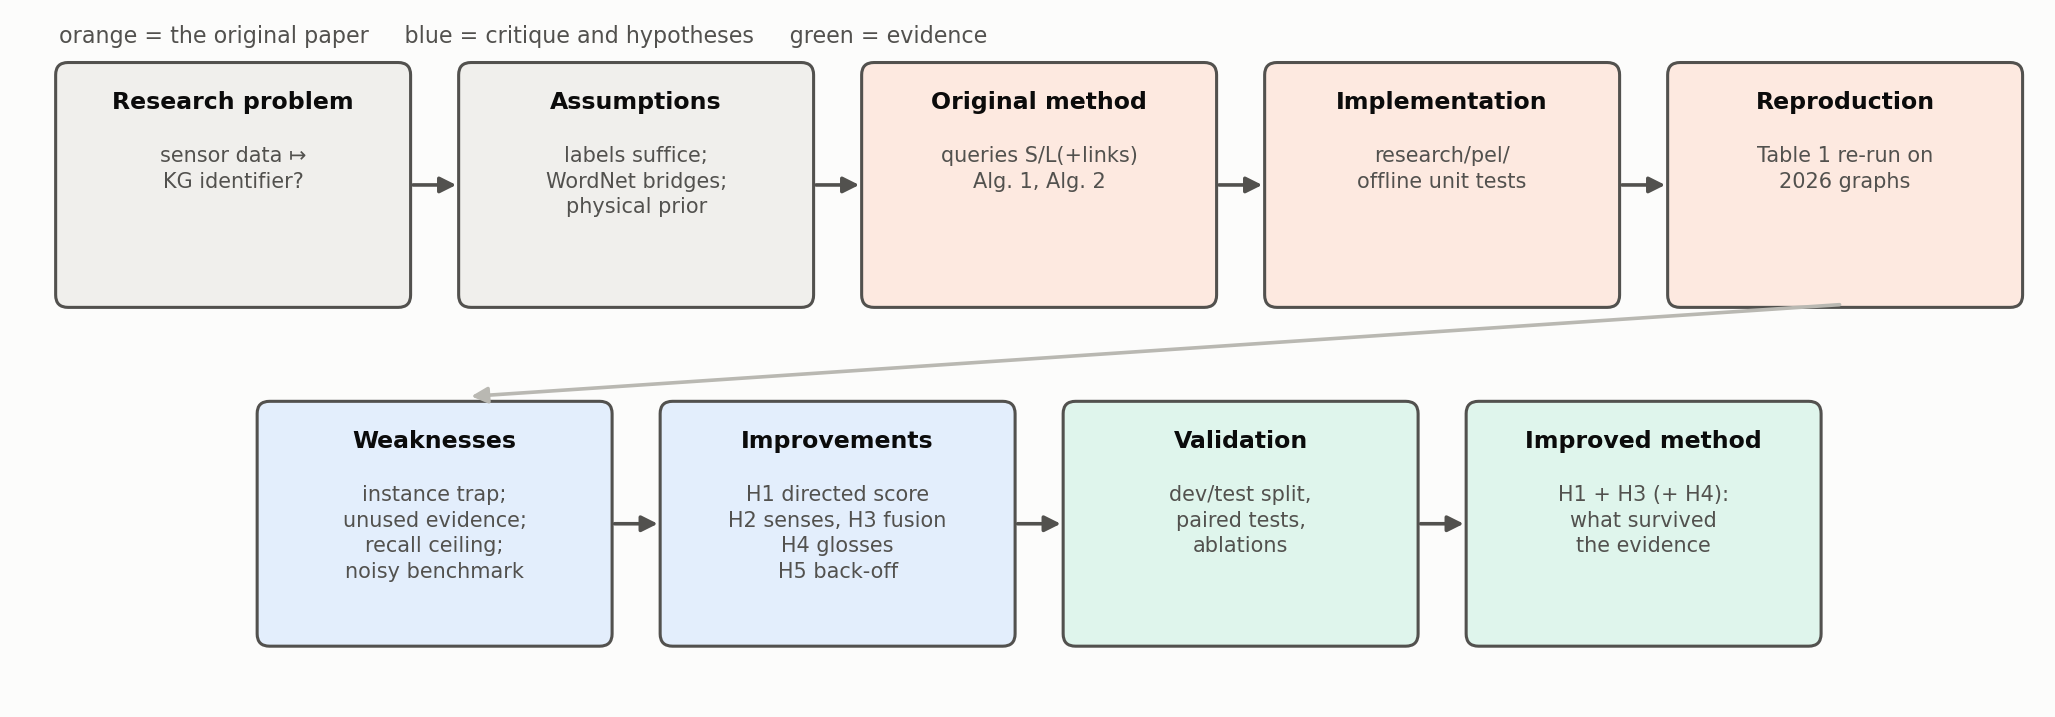

In [1]:
# Locate the research/ directory and make the real implementation importable.
import sys, json
from pathlib import Path
RESEARCH = Path.cwd().resolve()
while not (RESEARCH / "pel").is_dir():
    RESEARCH = RESEARCH.parent
for path in (RESEARCH, RESEARCH / "experiments"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
FIGURES = RESEARCH / "experiments" / "figures"
RESULTS = RESEARCH / "experiments" / "results"
%matplotlib inline
from IPython.display import Image
Image(filename=str(FIGURES / "concepts" / "research_journey.png"), width=950)

## 10.1 The essential ideas

1. **The problem [paper].** A robot's recogniser outputs strings; knowledge lives behind identifiers. Perceived-Entity Linking is the missing arrow, defined as recognition $f_r$ (sensor data → observation graph) followed by mapping $f_m$ (observation graph × knowledge graph → links).
2. **The world model can be public [paper].** Classical object recognition matches descriptions against a world model; the paper's central proposal is to let a Semantic Web knowledge graph be that model.
3. **The baseline [paper].** Candidate selection through WordNet synonyms (Algorithm 1), ordering by outgoing links as a popularity prior, disambiguation by WordNet similarity between candidate classes and the label (Algorithm 2).
4. **The benchmark [paper].** Labels of MS COCO and Visual Genome, three graphs, twelve conditions, hit@1/3/5.

## 10.2 Which original assumptions remain justified

| Assumption | Verdict after this study |
|---|---|
| A public knowledge graph can serve as the world model | **Justified.** For 55–88 % of labels the best simple condition already links correctly. |
| The entity-linking recipe (candidates, then ranking) transfers | **Justified.** |
| WordNet synonyms improve retrieval | **Justified:** candidate selection cuts “never retrieved” substantially on every graph. |
| Outgoing links approximate commonness | **Justified** — more than the authors expected. Popularity is the strongest single evidence in our ablations, although the paper's discussion doubts it. |
| Class/label WordNet similarity disambiguates | **Not justified in its published form**; justified once directed (H1) and combined with other evidence. |
| The label alone determines the target | **Not justified** for a sizeable share of Visual Genome labels (“base”, “can”). |

## 10.3 Limitations that were confirmed

* **Instance trap** — the symmetric similarity prefers instances of the perceived class over the class (half of WikiData's and four fifths of YAGO's ranking errors on development data).
* **One evidence at a time** — the original processes fail on different labels.
* **Recall ceiling** — for 21–30 % of Visual Genome entries the target is never retrieved; most of these are label/ground-truth mismatches no string method can bridge.
* **Fragility** — casing conventions and graph versions decide whether the method works at all (YAGO: 0.03 vs 0.51 hit@1 with lower-case vs capitalised labels; disambiguation neutral on YAGO 4, destructive on YAGO 4.5).
* **Benchmark** — noisy automatic ground truth, selection of well-documented concepts, no uncertainty estimates, NIL never evaluated.

## 10.4 What the experiments supported

| Change | Outcome on the test set |
|---|---|
| **H1** directed hypernym score | **supported**: +14 (WikiData) and +38 (YAGO) points over the original $f_c+f_d$; no effect on DBpedia |
| **H3** evidence fusion | **supported**: the largest single contribution; best or equal-best on every graph |
| **H4** gloss–description overlap | **weakly supported**: +1.7 to +2.7 points inside the fusion on WikiData and YAGO |
| **Combined** vs. original $f_c+f_d$ | +22 (WikiData), +45 (YAGO), +1 (DBpedia) points |
| **Combined** vs. best of the 12 original conditions | +0.3 to +6.3 points; **not robustly significant** |

## 10.5 What failed

* **H2 (noun / physical senses).** The most intuitive idea — it implements the paper's own “physical prior” — and the one with the most vivid examples. No effect alone; slightly *negative* inside the combined method on all five test settings.
* **H5 (class-label back-off).** A small gain on one graph, none on the others; not selected.
* **H1 or H4 as stand-alone replacements of Algorithm 2** repair it but do not beat doing no disambiguation at all.
* **The external baselines** of the paper (DBpedia Spotlight, AIDA) could not be re-run: both services were unreachable.

## 10.6 Remaining limitations

* Everything was measured on November 2026 snapshots of live graphs, on 80 + 600 (DBpedia: 150) labels.
* The reproduction is partial: rank agreement with the published table is high for DBpedia, moderate for WikiData, absent for YAGO; one published pattern (low hit@1 with high hit@5 for link-ordered queries on Visual Genome) could not be explained.
* No images, no detector, no robot — like the paper, the study starts from perfect labels.

## 10.7 Open questions

1. **Retrieval.** How much of the recall ceiling falls to redirects, disambiguation pages, parenthesised titles and both casings? (Upper bound from Chapter 7.5: 2–7 % of entries.)
2. **A better benchmark.** Human-verified targets, labels as detectors actually emit them, labels *without* a counterpart (to evaluate NIL), object classes separated from named individuals, and several acceptable targets per label.
3. **Context.** Does co-occurrence in the same observation graph (a “base” next to a “bat” and a “glove”) resolve label under-specification? This is the paper's first item of future work and needs images.
4. **Attributes.** Can colour, size and shape from the recogniser be matched against graph properties (the paper's orange-vs-grapefruit scenario)?
5. **Stability.** How can results be made reproducible when the world model is a live, changing graph? Archived snapshots; local copies.
6. **End-to-end value.** Does a correct link change what a robot can do?

## 10.8 Broader lessons

* **A symmetric measure used for a directed question is a bug waiting for data.** “Related to” and “a kind of” are different relations; the difference stayed invisible on the one graph where instances and classes do not share labels.
* **Vivid examples are not effect sizes.** `couch → picture frame` is memorable and real; restricting senses changed nothing measurable. `dog → andiron` is equally vivid and turned out to be a large effect. Only measurement tells them apart.
* **The strongest baseline is often the boring one.** “Take the most-linked entity with exactly this label” beats the paper's full pipeline on WikiData — and is the hardest thing to improve on.
* **Choose on one set, judge on another.** H2 and H5 looked useful on development data; DBpedia's best original process changed between development and test.
* **Report the comparison that could embarrass you.** Against the paper's disambiguation step the improvement is +22 to +45 points; against the best original condition it is a few points and not robust. Both numbers are true; only the second says whether the method advanced.
* **Benchmarks have ceilings.** When a fifth of the “errors” are artefacts of the ground truth, improving the method and improving the yardstick are equally important.

## 10.9 Where to go next in the repository

| To … | open |
|---|---|
| see every interpretation and deviation | `research/reproduction/specification.md` |
| read the numbers | `research/reproduction/results.md`, `research/improvements/results.md` |
| read the synthesis as a paper | `research/manuscript/improved_paper.md` |
| re-run everything | `research/README.md` |